# Build and inspect the stock-sector mapping

The financial CSV contains inconsistent sector labels and broad groups. Here we
build a separate mapping from **Euronext's published Industry Classification
Benchmark (ICB)**, inspect it, and save it for subsequent analyses.

We cover every stock history present at the dataset endpoint, including supported
predecessor ISINs, and report results separately for the five-year dependence sample.
No financial observations or existing notebooks are changed.

**Interpretation:** this is a current classification snapshot, not a point-in-time
classification history for 2021–2026. Applying it to past returns is retrospective
and may introduce look-ahead information in a predictive experiment.

ICB has four levels: **Industry → Supersector → Sector → Subsector**. Its top-level
Industry is closer to what the supplied data calls a sector. A difference between
an original label and a finer ICB label does not by itself show an error.

Sources: [ICB methodology](https://www.lseg.com/en/ftse-russell/industry-classification-benchmark-icb),
[Euronext Oslo directory](https://live.euronext.com/en/markets/oslo/equities/list).
Official classifications are preserved even when surprising. Unsupported cases
remain unresolved, without name-based guesses or vendor-label fallbacks, except for
the two explicitly user-confirmed manual bank assignments documented below.

In [1]:
REFRESH_WEB = False
INSPECTION_LEVEL = "Sector"  # Industry, Supersector, Sector, or Subsector

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from importlib.metadata import version
from html import escape, unescape
from threading import Lock
from tempfile import TemporaryDirectory
from time import perf_counter, sleep
import gzip
import hashlib
import json
import os
import re
import shutil
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import exchange_calendars as xcals
from IPython.display import HTML, display

SOURCE_NAME = "BMG9156K1018_10.09.2026_14.59.34.csv"
START, END = pd.Timestamp("2021-09-08"), pd.Timestamp("2026-09-08")
COVERAGE = 0.95
LEVELS = {"Industry": ("industry", 2), "Supersector": ("supersector", 4),
          "Sector": ("sector", 6), "Subsector": ("subsector", 8)}
assert INSPECTION_LEVEL in LEVELS
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Data" / SOURCE_NAME).is_file())
source = root / "Data" / SOURCE_NAME
output_path = root / "Data" / "stock_sector_mapping.csv"
cache_root = root / "Data" / "sector_mapping_sources"
offline = os.environ.get("SECTOR_MAPPING_OFFLINE") == "1"
if offline and REFRESH_WEB:
    raise ValueError("Offline verification cannot refresh web sources.")
digest = hashlib.sha256()
with source.open("rb") as handle:
    for block in iter(lambda: handle.read(1024 * 1024), b""):
        digest.update(block)
source_hash = digest.hexdigest()
packages = {p: version(p) for p in ["numpy", "pandas", "matplotlib", "exchange_calendars"]}
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 18)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
print(f"Financial source: {source.name} | endpoint {END.date()}")
print(f"Inspection level: {INSPECTION_LEVEL} | refresh: {REFRESH_WEB} | offline: {offline}")
display(pd.Series(packages, name="Version").to_frame())

Financial source: BMG9156K1018_10.09.2026_14.59.34.csv | endpoint 2026-09-08
Inspection level: Sector | refresh: False | offline: True


,Version
numpy,2.2.6
pandas,2.2.2
matplotlib,3.10.9
exchange_calendars,4.13.2


## 1. Reconstruct stock identities before looking up sectors

Link histories only when singleton CompanyId/SecurityId values support continuity
and the recorded spans do not overlap, plus the three explicit repository mappings.
This reproduces the identity rules in `EDA_sector_dependence.ipynb`; the notebook
does not execute or import that notebook. Simultaneous share classes stay distinct.
Prices are read only to reproduce the observed five-year selection later.

In [2]:
columns = ["Date", "ISIN", "SecurityId", "CompanyId", "Name", "Sector",
           "AdjustedPrice", "Turnover", "Currency"]
data = pd.read_csv(source, sep=";", decimal=",", usecols=columns, low_memory=False)
data["Date"] = pd.to_datetime(data["Date"], format="%Y-%m-%d")
for col in ["ISIN", "Name", "Sector", "Currency"]:
    data[col] = data[col].str.strip().replace("", pd.NA)
assert data["Date"].notna().all() and data["ISIN"].notna().all()
assert data["Date"].max() == END
assert data["Currency"].dropna().eq("NOK").all(), "Review turnover currency before ranking."
data = data.sort_values(["Date", "ISIN"], kind="stable")


def distinct_ids(values: pd.Series) -> tuple:
    """Retain all nonmissing source identities for a security."""
    return tuple(sorted(values.dropna().unique()))


profiles = data.groupby("ISIN", sort=True).agg(
    first=("Date", "min"), last=("Date", "max"),
    company_ids=("CompanyId", distinct_ids), security_ids=("SecurityId", distinct_ids),
    latest_name=("Name", "last"), latest_sector=("Sector", "last"),
)
history = {isin: {isin} for isin in profiles.index}
link_evidence = dict.fromkeys(profiles.index, "standalone ISIN; no accepted predecessor link")


def join_isins(isins: list[str], evidence: str) -> bool:
    """Join whole components only when every member's recorded span is disjoint."""
    if all(history[i] == history[isins[0]] for i in isins):
        return True
    members = set().union(*(history[i] for i in isins))
    spans = profiles.loc[sorted(members)].sort_values("first")
    if not spans["first"].iloc[1:].reset_index(drop=True).gt(
        spans["last"].iloc[:-1].reset_index(drop=True)
    ).all():
        return False
    for isin in members:
        history[isin] = members
        if not link_evidence[isin].startswith("explicit repository mapping"):
            link_evidence[isin] = evidence
    return True


explicit = {
    "Kongsberg": ["NO0003043309", "NO0013536151"],
    "Frontline": ["BMG368191034", "BMG3682E1012", "BMG3682E1921", "CY0200352116"],
    "Tomra": ["NO0005668905", "NO0012470089"],
}
for name, isins in explicit.items():
    assert set(isins).issubset(profiles.index)
    assert join_isins(isins, f"explicit repository mapping: {name}")

stable = profiles.loc[profiles["company_ids"].map(len).eq(1)
                      & profiles["security_ids"].map(len).eq(1)]
unresolved_identifier_groups = []
for keys, group in stable.groupby(["company_ids", "security_ids"]):
    if len(group) > 1 and not join_isins(
        group.index.tolist(), "same singleton CompanyId/SecurityId; disjoint spans"
    ):
        unresolved_identifier_groups.append({"identifiers": str(keys),
                                             "ISINs": tuple(group.index)})

stock_for_isin = {}
for isin, members in history.items():
    current = profiles.loc[sorted(members)].sort_values(["last", "first"]).index[-1]
    stock_for_isin[isin] = current
data["stock_id"] = data["ISIN"].map(stock_for_isin)
endpoint_isins = set(data.loc[data["Date"].eq(END), "ISIN"])
candidates = sorted({stock_for_isin[i] for i in endpoint_isins})
candidate_data = data.loc[data["stock_id"].isin(candidates)]
metadata = candidate_data.groupby("stock_id").agg(
    name=("Name", "last"), company_id=("CompanyId", "last"), sector=("Sector", "last"),
    source_start=("Date", "min"), source_end=("Date", "max"),
    historical_isins=("ISIN", "nunique"), sector_labels=("Sector", distinct_ids),
)
metadata["endpoint_isin"] = metadata.index
metadata["sector_changed"] = metadata["sector_labels"].map(len).gt(1)
lineage = profiles.reset_index()
lineage["stock_id"] = lineage["ISIN"].map(stock_for_isin)
lineage["link_evidence"] = lineage["ISIN"].map(link_evidence)
lineage["endpoint_candidate"] = lineage["stock_id"].isin(candidates)
lineage["joined"] = lineage["ISIN"].map(lambda i: len(history[i]) > 1)
print(f"Loaded {len(data):,} rows; reconstructed {len(candidates)} candidate histories.")
print(f"Joined histories: {lineage.loc[lineage.endpoint_candidate & lineage.joined, 'stock_id'].nunique()}; "
      f"unresolved identifier groups: {len(unresolved_identifier_groups)}.")

Loaded 1,876,617 rows; reconstructed 292 candidate histories.
Joined histories: 14; unresolved identifier groups: 0.


### Identify the five-year reference sample

Use the XOSL session calendar, valid adjusted prices at both boundaries, and at least
95% price coverage before any interpolation. Conflicting/invalid prices are unavailable.
Among eligible classes of an identified company, retain the largest summed valid
NOK turnover, breaking ties by endpoint ISIN. This sample is used only for inspection;
it does not restrict which endpoint histories receive a mapping.

In [3]:
calendar = xcals.get_calendar("XOSL", start=START - pd.Timedelta(days=14), end=END)
sessions = calendar.sessions_in_range(START, END).tz_localize(None)
previous_session = calendar.previous_session(sessions[0]).tz_localize(None)
price_sessions = sessions.insert(0, previous_session)
assert sessions[0] == START and sessions[-1] == END
in_window = data["Date"].between(START, END)
non_sessions = data.loc[in_window & ~data["Date"].isin(sessions)]
calendar_audit = non_sessions.groupby("Date").size().rename("excluded_source_rows").to_frame()
print(f"Expected sessions: {len(sessions):,}; preceding session: {previous_session.date()}")
print(f"Excluded non-session source rows: {len(non_sessions):,} across {len(calendar_audit)} dates")

raw = candidate_data.loc[candidate_data["Date"].isin(price_sessions)].copy()
keys = ["stock_id", "Date"]
grouped = raw.groupby(keys, sort=True)
price_variants = grouped["AdjustedPrice"].nunique(dropna=False)
turnover_variants = grouped["Turnover"].nunique(dropna=False)
clean = raw.drop_duplicates(keys).set_index(keys).sort_index()
clean["raw_price"] = clean["AdjustedPrice"]
clean["price_conflict"] = price_variants.gt(1)
clean["duplicate_rows"] = grouped.size() - 1
clean["recorded_invalid"] = ~(np.isfinite(clean["raw_price"]) & clean["raw_price"].gt(0))
clean["price"] = clean["raw_price"].where(~clean["price_conflict"] & ~clean["recorded_invalid"])
clean["usable_turnover"] = clean["Turnover"].where(
    turnover_variants.eq(1) & np.isfinite(clean["Turnover"]) & clean["Turnover"].ge(0)
)
all_prices = clean["price"].unstack("stock_id").reindex(index=price_sessions, columns=candidates)
recorded = clean["ISIN"].unstack("stock_id").reindex(index=price_sessions, columns=candidates).notna()
prices_in_window = all_prices.loc[sessions]
window_clean = clean.loc[clean.index.get_level_values("Date").isin(sessions)]

audit = metadata.copy()
audit["expected_sessions"] = len(sessions)
audit["available_prices"] = prices_in_window.count()
audit["coverage_pct"] = 100 * audit["available_prices"] / len(sessions)
audit["absent_records"] = (~recorded.loc[sessions]).sum()
audit["recorded_unavailable_prices"] = (recorded.loc[sessions] & prices_in_window.isna()).sum()
audit["missing_prices"] = prices_in_window.isna().sum()
audit["price_conflict_sessions"] = window_clean["price_conflict"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["recorded_invalid_sessions"] = window_clean["recorded_invalid"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["duplicate_rows"] = window_clean["duplicate_rows"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["boundary_ok"] = prices_in_window.iloc[0].notna() & prices_in_window.iloc[-1].notna()
audit["coverage_ok"] = audit["available_prices"].ge(np.ceil(COVERAGE * len(sessions)))
audit["five_year_turnover"] = window_clean["usable_turnover"].groupby(level=0).sum(min_count=1).reindex(candidates)
audit["missing_turnover_sessions"] = len(sessions) - window_clean["usable_turnover"].groupby(level=0).count().reindex(candidates, fill_value=0)
audit["coverage_eligible"] = audit["boundary_ok"] & audit["coverage_ok"]
eligible = audit.loc[audit["coverage_eligible"]].copy()
# Missing issuer IDs stay distinct; they cannot be collapsed by company-name similarity.
eligible["issuer_key"] = [f"company:{int(c)}" if pd.notna(c) else f"unidentified:{i}"
                          for i, c in eligible["company_id"].items()]
assert eligible["five_year_turnover"].notna().all(), "Review unavailable turnover before class selection."
ranked = eligible.sort_values(["five_year_turnover", "endpoint_isin"], ascending=[False, True])
selected = ranked.drop_duplicates("issuer_key").sort_values(["sector", "name"], na_position="last")
stock_ids = selected.index.tolist()
audit["selected"] = audit.index.isin(stock_ids)
audit["status"] = np.select(
    [~audit["boundary_ok"], ~audit["coverage_ok"], ~audit["selected"]],
    ["boundary unavailable", "coverage below 95%", "other qualifying share class selected"],
    default="selected",
)
lineage["selection_status"] = lineage["stock_id"].map(audit["status"]).fillna("no endpoint observation")
funnel = pd.Series({
    "Endpoint ISINs": len(endpoint_isins), "Reconstructed candidate histories": len(audit),
    "Valid boundary prices": int(audit["boundary_ok"].sum()),
    "Boundaries and >=95% price coverage": len(eligible), "Selected share classes": len(selected),
}, name="stocks").to_frame()
display(funnel.rename(columns={"stocks": "Stocks remaining"}))
print(f"Selected {len(selected)} stocks; {len(audit) - len(eligible)} failed endpoint/coverage checks; "
      f"{len(eligible) - len(selected)} additional qualifying share classes excluded.")

endpoint_profiles = metadata.copy()
endpoint_profiles["selected_five_year"] = endpoint_profiles.index.isin(stock_ids)
endpoint_lineage = lineage.loc[lineage["endpoint_candidate"]].copy()
endpoint_lineage["selected_five_year"] = endpoint_lineage["stock_id"].isin(stock_ids)
print(f"Export universe: {len(endpoint_profiles)} endpoint histories, "
      f"{len(endpoint_lineage)} distinct source ISINs including predecessors.")
display(endpoint_lineage.loc[endpoint_lineage["joined"],
        ["ISIN", "stock_id", "latest_name", "first", "last", "link_evidence"]])
display(pd.DataFrame(unresolved_identifier_groups))

Expected sessions: 1,257; preceding session: 2021-09-07
Excluded non-session source rows: 6,777 across 24 dates


,Stocks remaining
Endpoint ISINs,292
Reconstructed candidate histories,292
Valid boundary prices,205
Boundaries and >=95% price coverage,197
Selected share classes,195


Selected 195 stocks; 95 failed endpoint/coverage checks; 2 additional qualifying share classes excluded.
Export universe: 292 endpoint histories, 308 distinct source ISINs including predecessors.


,ISIN,stock_id,latest_name,first,last,link_evidence
13,BMG1466R1732,BMG1466R1732,BORR DRILLING,2021-12-14,2026-09-08,same singleton CompanyId/SecurityId; disjoint ...
14,BMG1466R2078,BMG1466R1732,BORR DRILLING,2017-08-30,2021-12-13,same singleton CompanyId/SecurityId; disjoint ...
25,BMG368191034,CY0200352116,Frontline,1997-07-07,1998-05-11,explicit repository mapping: Frontline
26,BMG3682E1012,CY0200352116,Frontline,1998-05-12,1998-11-06,explicit repository mapping: Frontline
27,BMG3682E1921,CY0200352116,FRONTLINE,1998-11-09,2023-01-12,explicit repository mapping: Frontline
...,...,...,...,...,...,...
1035,NO0012953720,NO0012953720,HUNTER GROUP,2023-07-03,2026-09-08,same singleton CompanyId/SecurityId; disjoint ...
1039,NO0013033795,NO0013033795,CIRCIO HOLDING,2023-10-04,2026-09-08,same singleton CompanyId/SecurityId; disjoint ...
1043,NO0013119255,NO0013119255,INTEROIL EXPL PROD,2024-01-23,2026-09-08,same singleton CompanyId/SecurityId; disjoint ...
1045,NO0013162693,NO0013162693,NORDIC MINING,2024-03-13,2026-09-08,same singleton CompanyId/SecurityId; disjoint ...


""


## 2. Collect a reproducible official-source snapshot

The directory is paginated and contains venue codes XOSL, XOAS, and MERK. Collect
all advertised pages, then match exact ISINs. Search Euronext by exact ISIN only for
stocks absent from the directory; a missing current-directory entry is not proof
that a company was delisted. Each accepted page must explicitly identify the ISIN.

**Cache:** `Data/sector_mapping_sources/` contains immutable compressed responses,
a timestamped request manifest, and a pointer to the active snapshot. The manifest
records attempted URLs/queries, UTC retrieval times, status, hashes, and errors.
`REFRESH_WEB=False` reuses existing responses and fetches missing ones. A refresh
starts a new snapshot and preserves previous snapshots. Cached failures are shown
as unresolved; refresh to retry them. A completed snapshot runs without network
access or a Firecrawl installation.

Live collection requires the authenticated **Firecrawl CLI** (`firecrawl --status`)
and uses at most two concurrent requests. Credentials are never stored here.
Requests are spaced to respect the current account's ten-per-minute limit;
rate-limit responses also honor the server's retry delay. Transient CLI failures
receive one retry. Missing pages are not relabelled as valid.

In [4]:
cache_root.mkdir(parents=True, exist_ok=True)
latest_path = cache_root / "latest.json"
if latest_path.exists() and not REFRESH_WEB:
    snapshot_id = json.loads(latest_path.read_text())["snapshot_id"]
else:
    snapshot_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
snapshot_dir = cache_root / "snapshots" / snapshot_id
snapshot_dir.mkdir(parents=True, exist_ok=True)
manifest_path = snapshot_dir / "manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    assert manifest["financial_source_sha256"] == source_hash, "Source changed; refresh the snapshot."
else:
    manifest = {"snapshot_id": snapshot_id, "created_at": datetime.now(timezone.utc).isoformat(),
                "financial_source": SOURCE_NAME, "financial_source_sha256": source_hash,
                "packages": packages, "requests": {}}
    manifest_path.write_text(json.dumps(manifest, indent=2))
latest_path.write_text(json.dumps({"snapshot_id": snapshot_id}, indent=2))
cache_lock = Lock()
request_start_lock = Lock()
next_request_at = 0.0
network_requests = 0


def cached_request(key: str, kind: str) -> tuple[dict, dict]:
    """Fetch a page/search once, retaining the exact response and its provenance."""
    global network_requests, next_request_at
    request_id = hashlib.sha256(f"{kind}:{key}".encode()).hexdigest()
    with cache_lock:
        entry = manifest["requests"].get(request_id)
    if entry is not None and (entry["status"] == "retrieved" or manifest.get("collection_complete", False)):
        path = root / entry["cache_path"]
        raw_bytes = gzip.decompress(path.read_bytes())
        assert hashlib.sha256(raw_bytes).hexdigest() == entry["content_sha256"]
        return json.loads(raw_bytes), entry.copy()
    if offline:
        raise RuntimeError(f"Offline snapshot is missing {kind}: {key}")
    if shutil.which("firecrawl") is None:
        raise RuntimeError("Live collection needs the authenticated Firecrawl CLI.")
    attempts = list(entry["attempts"]) if entry is not None else []
    previous_entries = ([*entry.get("previous_entries", []),
                         {k: v for k, v in entry.items() if k != "previous_entries"}]
                        if entry is not None else [])
    payload = {}
    status = "retrieval_failed"
    for attempt in range(2):
        retrieved_at = datetime.now(timezone.utc).isoformat()
        with TemporaryDirectory() as temp:
            destination = Path(temp) / "response.json"
            args = (["firecrawl", "scrape", key, "--format", "markdown,html"]
                    if kind == "page" else
                    ["firecrawl", "search", key, "--limit", "5", "--json"])
            args += ["-o", str(destination)]
            # Reserve starts jointly across both workers: no more than ten per minute.
            with request_start_lock:
                delay = next_request_at - perf_counter()
                while delay > 0:
                    sleep(min(delay, 60))
                    delay = next_request_at - perf_counter()
                next_request_at = perf_counter() + 6.5
            with cache_lock:
                network_requests += 1
            try:
                result = subprocess.run(args, capture_output=True, text=True, timeout=180)
                if result.returncode == 0 and destination.exists():
                    payload = json.loads(destination.read_text())
                    if payload.get("success") is not False:
                        status = "retrieved"
                        attempts.append({"retrieved_at": retrieved_at, "status": status})
                        break
                    error = str(payload.get("error", "Provider reported an unsuccessful request"))[-1500:]
                else:
                    error = (result.stderr or result.stdout)[-1500:]
            except (subprocess.TimeoutExpired, json.JSONDecodeError) as exc:
                error = f"{type(exc).__name__}: request did not produce a valid JSON response"
            attempts.append({"retrieved_at": retrieved_at, "status": "retrieval_failed", "error": error})
            retry = re.search(r"retry after (\d+)s", error, flags=re.I)
            if retry:
                with request_start_lock:
                    next_request_at = max(next_request_at, perf_counter() + int(retry.group(1)) + 1)
    raw_bytes = json.dumps(payload, ensure_ascii=False, sort_keys=True).encode()
    content_hash = hashlib.sha256(raw_bytes).hexdigest()
    path = snapshot_dir / f"{request_id}_{content_hash[:16]}.json.gz"
    path.write_bytes(gzip.compress(raw_bytes, mtime=0))
    entry = {"request_kind": kind, "request": key,
             "retrieved_at": datetime.now(timezone.utc).isoformat(),
             "status": status, "content_sha256": hashlib.sha256(raw_bytes).hexdigest(),
             "cache_path": path.relative_to(root).as_posix(), "attempts": attempts,
             "previous_entries": previous_entries}
    with cache_lock:
        manifest["requests"][request_id] = entry
        manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
    return payload, entry.copy()


def directory_links(payload: dict) -> set[str]:
    """Extract only exact Oslo equity product URLs from directory HTML."""
    return set(re.findall(
        r'https://live\.euronext\.com/en/product/equities/[A-Z0-9]{12}-(?:XOSL|XOAS|MERK)',
        unescape(payload.get("html", ""))))


def collect_directory() -> tuple[dict[str, set[str]], pd.DataFrame]:
    """Visit all advertised page numbers, checking that pagination actually changes."""
    pending, seen, rows, urls = {0}, set(), [], set()
    page_signatures = set()
    while pending:
        page = min(pending)
        pending.remove(page)
        url = f"https://live.euronext.com/en/markets/oslo/equities/list?page={page}"
        payload, entry = cached_request(url, "page")
        found = directory_links(payload)
        signature = tuple(sorted(found))
        status = entry["status"]
        if status == "retrieved":
            if not found:
                status = "empty_directory_page"
            elif signature in page_signatures:
                status = "repeated_directory_page"
            else:
                page_signatures.add(signature)
                urls.update(found)
        seen.add(page)
        advertised = {int(n) for n in re.findall(
            r'/en/markets/oslo/equities/list\?page=(\d+)', unescape(payload.get("html", "")))}
        pending.update(advertised - seen)
        rows.append({"page": page, "url": url, "links": len(found), "status": status,
                     "retrieved_at": entry["retrieved_at"]})
    by_isin = {}
    for url in sorted(urls):
        isin = url.rsplit("/", 1)[1].split("-")[0]
        by_isin.setdefault(isin, set()).add(url + "/market-information")
    return by_isin, pd.DataFrame(rows)


def parse_icb(payload: dict, expected_isin: str) -> dict:
    """Validate exact security identity and parse a complete, internally coherent ICB table."""
    blank = {f"icb_{prefix}_{suffix}": "" for prefix, _ in LEVELS.values()
             for suffix in ("code", "name")}
    result = {**blank, "classification_status": "unresolved", "unresolved_reason": ""}
    metadata_web = payload.get("metadata", {})
    if metadata_web.get("statusCode", 200) >= 400:
        return {**result, "unresolved_reason": "page_not_found"}
    text = payload.get("markdown", "")
    identities = set(re.findall(r'\|\s*ISIN Code\s*\|\s*([A-Z0-9]{12})\s*\|', text))
    if identities != {expected_isin}:
        return {**result, "unresolved_reason": "security_identity_not_verified"}
    sections = re.split(r'ICB\s+SECTORIAL\s+CLASSIFICATION', text, flags=re.I)
    if len(sections) == 1:
        return {**result, "unresolved_reason": "no_published_icb_table"}
    values = {}
    for label, (prefix, width) in LEVELS.items():
        hits = set(re.findall(
            rf'\|\s*{label}\s*\|\s*\*{{0,2}}(\d{{{width}}}),\s*([^|\n]+?)\*{{0,2}}\s*\|',
            "\n".join(sections[1:]), flags=re.I))
        hits = {(number, name.strip().strip("*").strip()) for number, name in hits}
        if len(hits) != 1 or not next(iter(hits))[1]:
            reason = "conflicting_icb_table" if len(hits) > 1 else "incomplete_or_malformed_icb_table"
            return {**result, "unresolved_reason": reason}
        number, name = next(iter(hits))
        values[f"icb_{prefix}_code"] = number
        values[f"icb_{prefix}_name"] = name
    codes = [values[f"icb_{prefix}_code"] for prefix, _ in LEVELS.values()]
    if not all(child.startswith(parent) for parent, child in zip(codes[:-1], codes[1:])):
        return {**result, "unresolved_reason": "inconsistent_icb_hierarchy"}
    return {**result, **values, "classification_status": "verified"}


directory, directory_audit = collect_directory()
print(f"Snapshot {snapshot_id}: {len(directory)} directory ISINs across {len(directory_audit)} pages.")
display(directory_audit)

Snapshot 20261117T140247570260Z: 291 directory ISINs across 3 pages.


,page,url,links,status,retrieved_at
0,0,https://live.euronext.com/en/markets/oslo/equi...,100,retrieved,2026-11-17T14:02:47.572954+00:00
1,1,https://live.euronext.com/en/markets/oslo/equi...,100,retrieved,2026-11-17T14:03:58.781050+00:00
2,2,https://live.euronext.com/en/markets/oslo/equi...,91,retrieved,2026-11-17T14:04:00.475025+00:00


### Resolve and classify each endpoint security

Accept only pages whose identification table contains the expected ISIN and whose
ICB table contains all four consistent levels. If multiple candidate pages disagree,
leave the security unresolved. An explicit classification is never inferred from
the company's name, the old sector label, a related company, or its returns.

**Manual assignments requested by the user:** Grong Sparebank (NO0010636491)
and Romerike Sparebank (NO0010808405) are assigned to Financials → Banks → Banks
→ Banks using the existing ICB bank hierarchy. Their status is manual, not
Euronext-verified. The original page outcomes remain available in the evidence
columns, and a classification note records the user's confirmation.


In [5]:
def classify_endpoint(isin: str) -> dict:
    """Resolve exact-ISIN official pages and retain disagreement as an unresolved case."""
    urls = set(directory.get(isin, set()))
    search_reference = ""
    if not urls:
        query = f'site:live.euronext.com "{isin}"'
        payload, search_entry = cached_request(query, "search")
        search_reference = search_entry["cache_path"]
        search_results = payload.get("data", {}).get("web", payload.get("web", []))
        for hit in search_results:
            match = re.search(
                rf'https://live\.euronext\.com/[a-z]{{2}}/product/equities/({isin}-(?:XOSL|XOAS|MERK))(?:/|$)',
                hit.get("url", ""), flags=re.I)
            if match:
                urls.add(f"https://live.euronext.com/en/product/equities/{match.group(1).upper()}/market-information")
    blank = {f"icb_{prefix}_{suffix}": "" for prefix, _ in LEVELS.values()
             for suffix in ("code", "name")}
    base = {"stock_id": isin, **blank, "classification_status": "unresolved",
            "unresolved_reason": "no_exact_isin_page", "classification_isin": "",
            "listing_venue": "", "source_url": "", "retrieved_at": "",
            "evidence_cache": "", "candidate_source_urls": json.dumps(sorted(urls)),
            "search_evidence_cache": search_reference, "page_outcomes": ""}
    parsed = []
    for url in sorted(urls):
        payload, entry = cached_request(url, "page")
        item = parse_icb(payload, isin) if entry["status"] == "retrieved" else {
            **blank, "classification_status": "unresolved", "unresolved_reason": "retrieval_failed"}
        parsed.append({**item, "source_url": url, "retrieved_at": entry["retrieved_at"],
                       "evidence_cache": entry["cache_path"],
                       "listing_venue": url.split("/")[-2].rsplit("-", 1)[-1]})
    outcomes = [{k: item[k] for k in ["source_url", "classification_status", "unresolved_reason",
                                    "retrieved_at", "evidence_cache"]} for item in parsed]
    base["page_outcomes"] = json.dumps(outcomes, ensure_ascii=False, sort_keys=True)
    valid = [item for item in parsed if item["classification_status"] == "verified"]
    signatures = {tuple(item[k] for k in blank) for item in valid}
    if len(signatures) > 1:
        return {**base, "unresolved_reason": "conflicting_official_pages"}
    if valid:
        return {**base, **valid[0], "classification_isin": isin}
    if parsed:
        return {**base, **parsed[0],
                "unresolved_reason": "; ".join(sorted({item["unresolved_reason"] for item in parsed}))}
    if search_reference and search_entry["status"] != "retrieved":
        base["unresolved_reason"] = "search_retrieval_failed"
    return base


classification_rows = []
with ThreadPoolExecutor(max_workers=2) as pool:
    futures = {pool.submit(classify_endpoint, isin): isin for isin in candidates}
    for future in as_completed(futures):
        classification_rows.append(future.result())
        if len(classification_rows) % 25 == 0 or len(classification_rows) == len(candidates):
            print(f"Processed {len(classification_rows)}/{len(candidates)} endpoint histories", flush=True)
classifications = pd.DataFrame(classification_rows).set_index("stock_id").sort_index()
assert set(classifications.index) == set(candidates)
# Preserve the official retrieval outcomes before the two explicit manual additions.
official_classifications = classifications.copy()
classifications["classification_publisher"] = "Euronext Live"
classifications["classification_note"] = ""
manual_bank_isins = ("NO0010636491", "NO0010808405")
bank_hierarchy = {
    "icb_industry_code": "30", "icb_industry_name": "Financials",
    "icb_supersector_code": "3010", "icb_supersector_name": "Banks",
    "icb_sector_code": "301010", "icb_sector_name": "Banks",
    "icb_subsector_code": "30101010", "icb_subsector_name": "Banks",
}
for isin in manual_bank_isins:
    assert isin in classifications.index
    assert official_classifications.loc[isin, "classification_status"] == "unresolved"
    for column, value in bank_hierarchy.items():
        classifications.loc[isin, column] = value
    classifications.loc[isin, "classification_status"] = "manual"
    classifications.loc[isin, "classification_isin"] = isin
    classifications.loc[isin, "unresolved_reason"] = ""
    classifications.loc[isin, "classification_publisher"] = "Manual (user-confirmed)"
    classifications.loc[isin, "classification_note"] = (
        "User confirmed this company is a bank; assigned the ICB Banks hierarchy manually. "
        "The Euronext page does not publish an ICB classification.")
endpoint_mapping = endpoint_profiles.join(classifications, validate="one_to_one")
manifest["collection_complete"] = True
manifest["endpoint_histories"] = len(candidates)
manifest["selected_histories"] = len(stock_ids)
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print(f"Network requests in this run: {network_requests}; verified endpoint classifications: "
      f"{endpoint_mapping['classification_status'].eq('verified').sum()}/{len(endpoint_mapping)}")

Processed 25/292 endpoint histories


Processed 50/292 endpoint histories


Processed 75/292 endpoint histories


Processed 100/292 endpoint histories


Processed 125/292 endpoint histories


Processed 150/292 endpoint histories


... (3 outputs left out)

Processed 250/292 endpoint histories


Processed 275/292 endpoint histories


Processed 292/292 endpoint histories


Network requests in this run: 0; verified endpoint classifications: 288/292


## 3. Inspect coverage before comparing classifications

Count endpoint histories, not alias ISINs, so a security-code change does not
inflate coverage. Every unresolved security remains in the output. Failures to
retrieve a source are distinguished from pages that publish no ICB classification.
The selected sample is recomputed from the financial source above.
Manual assignments are counted separately from verified Euronext classifications.

In [6]:
samples = {"All endpoint histories": endpoint_mapping,
           "Five-year selected sample": endpoint_mapping.loc[stock_ids]}
coverage_rows = []
for sample_name, sample in samples.items():
    mapped = sample["classification_status"].isin(["verified", "manual"])
    coverage_rows.append({"Sample": sample_name, "Histories": len(sample),
                          "Verified": int(sample["classification_status"].eq("verified").sum()),
                          "Manual": int(sample["classification_status"].eq("manual").sum()),
                          "Mapped": int(mapped.sum()), "Unresolved": int((~mapped).sum()),
                          "Mapped percent": 100 * mapped.mean()})
coverage_summary = pd.DataFrame(coverage_rows).set_index("Sample")
display(coverage_summary.round(2))
unresolved = endpoint_mapping.loc[endpoint_mapping["classification_status"].eq("unresolved")]
unresolved_counts = unresolved.groupby("unresolved_reason").agg(
    endpoint_histories=("name", "size"), selected_histories=("selected_five_year", "sum"))
display(unresolved_counts)
print("Directory pages all usable:", directory_audit["status"].eq("retrieved").all())
print("The directory reflects retrieval time; the dataset endpoint is earlier.")
request_audit = pd.DataFrame([
    {"Kind": entry["request_kind"], "Request": entry["request"], "Status": entry["status"],
     "Attempts": len(entry["attempts"]), "Retrieved at": entry["retrieved_at"],
     "Evidence": entry["cache_path"]}
    for entry in manifest["requests"].values()])
display(pd.crosstab(request_audit["Kind"], request_audit["Status"]))
print("The manifest also preserves earlier failed or unused URL attempts; "
      "mapping coverage above counts the final security-level outcomes.")

,Histories,Verified,Manual,Mapped,Unresolved,Mapped percent
Sample,,,,,,
All endpoint histories,292,288,2,290,2,99.32
Five-year selected sample,195,193,2,195,0,100.00


,endpoint_histories,selected_histories
unresolved_reason,,
security_identity_not_verified,2,0


Directory pages all usable: True
The directory reflects retrieval time; the dataset endpoint is earlier.


Status,retrieval_failed,retrieved
Kind,,
page,2,297
search,1,15


The manifest also preserves earlier failed or unused URL attempts; mapping coverage above counts the final security-level outcomes.


### Search and inspect the complete endpoint table

Search by company, ISIN, original label, ICB label/code, or unresolved reason.
The table contains every endpoint history and links directly to source pages.
All four levels are retained regardless of the inspection-level setting.
HTML filtering works in a trusted Jupyter notebook; browser Find also searches
the full rendered table.

In [7]:
def searchable_table(frame: pd.DataFrame, table_id: str) -> None:
    """Display every row with safe text escaping, source links, and a search field."""
    safe = frame.fillna("").astype(str).map(escape)
    if "Source" in frame:
        safe["Source"] = [
            f'<a href="{escape(url, quote=True)}" target="_blank" rel="noopener">Official page</a>'
            if url.startswith("https://live.euronext.com/") else ""
            for url in frame["Source"].fillna("")]
    table = safe.to_html(index=False, escape=False, table_id=table_id, border=0)
    action = (
        f"for (const row of document.querySelectorAll('#{table_id} tbody tr')) "
        "{row.style.display=row.textContent.toLowerCase().includes(this.value.toLowerCase())?'':'none';}")
    display(HTML(
        f'<label>Search: <input aria-label="Search mapping table" '
        f'oninput="{escape(action, quote=True)}" style="width:340px;margin:8px"></label>'
        '<div style="overflow:auto;max-height:540px;border:1px solid #ddd">'
        f'{table}</div>'))


inspection = endpoint_mapping.reset_index().rename(columns={
    "stock_id": "Endpoint ISIN", "name": "Company", "sector": "Original sector",
    "selected_five_year": "Selected five-year", "classification_status": "Status",
    "unresolved_reason": "Unresolved reason", "source_url": "Source",
    "company_id": "Source company ID", "sector_labels": "Historical source labels"})
for label, (prefix, _) in LEVELS.items():
    inspection[label] = [
        f"{name} ({number})" if number else ""
        for name, number in zip(inspection[f"icb_{prefix}_name"], inspection[f"icb_{prefix}_code"])]
inspection_columns = ["Endpoint ISIN", "Company", "Source company ID", "Original sector",
                      "Historical source labels", "Selected five-year", *LEVELS,
                      "Status", "classification_publisher", "classification_note",
                      "Unresolved reason", "Source", "retrieved_at"]
searchable_table(inspection[inspection_columns], "endpoint-icb-mapping")

Endpoint ISIN,Company,Source company ID,Original sector,Historical source labels,Selected five-year,Industry,Supersector,Sector,Subsector,Status,classification_publisher,classification_note,Unresolved reason,Source,retrieved_at
BE0003816338,"CMB,TECH",,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:02:49.292816+00:00
BMG0451H2087,ARCHER,,Energy,"('Energy',)",False,Energy (60),Energy (6010),"Oil, Gas and Coal (601010)",Oil Equipment and Services (60101030),verified,Euronext Live,,,Official page,2026-11-17T14:02:49.292905+00:00
BMG0670A1099,AUTOSTORE HOLDINGS,,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Engineering (502040),Machinery: Industrial (50204000),verified,Euronext Live,,,Official page,2026-11-17T14:02:53.458791+00:00
BMG0702P1086,BW ENERGY LIMITED,12748.0,Energy,"('Energy',)",True,Energy (60),Energy (6010),"Oil, Gas and Coal (601010)",Oil: Crude Producers (60101010),verified,Euronext Live,,,Official page,2026-11-17T14:02:54.094194+00:00
BMG1466R1732,BORR DRILLING,12565.0,Energy,"('Energy',)",False,Energy (60),Energy (6010),"Oil, Gas and Coal (601010)",Oil Equipment and Services (60101030),verified,Euronext Live,,,Official page,2026-11-17T14:02:58.291142+00:00
BMG1738J1247,BW OFFSHORE LTD,8108.0,Energy,"('Energy',)",True,Energy (60),Energy (6010),"Oil, Gas and Coal (601010)",Oil Equipment and Services (60101030),verified,Euronext Live,,,Official page,2026-11-17T14:02:58.702360+00:00
BMG4209G2077,GULF KEYSTONE PET,,Energy,"('Energy',)",False,Energy (60),Energy (6010),"Oil, Gas and Coal (601010)",Oil: Crude Producers (60101010),verified,Euronext Live,,,Official page,2026-11-17T14:03:10.514350+00:00
BMG4660A1036,HIMALAYA SHIPPING,,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:04:02.180737+00:00
BMG5137R1088,JINHUI SHIPP TRANS,2446.0,Industrials,"('Industrials',)",True,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:03:19.333497+00:00
BMG6682J1036,NORTHERN OCEAN LTD,12750.0,Energy,"('Energy',)",True,Energy (60),Energy (6010),"Oil, Gas and Coal (601010)",Oil Equipment and Services (60101030),verified,Euronext Live,,,Official page,2026-11-17T14:07:01.285563+00:00


## 4. Compare the old labels with the ICB hierarchy

Cross-tabulate the supplied sector labels against ICB Industry and Sector. Industry
is the closest broad comparison; Sector reveals finer divisions. A split across
different levels is expected and must not be counted automatically as a correction.
Unresolved cases remain visible as a separate column.

icb_industry_name,Basic Materials,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Real Estate,Technology,Telecommunications,Unresolved,Utilities
sector,,,,,,,,,,,,
Bank,0,0,0,0,2,0,0,0,0,0,0,0
Basic Materials,14,0,0,0,0,0,0,0,0,0,0,0
Consumer Discretionary,0,14,0,0,0,0,0,0,1,0,0,0
Consumer Staples,0,0,26,0,0,0,0,0,0,0,0,0
Energy,0,0,0,55,0,0,2,0,0,0,0,0
Financials,0,0,0,0,42,0,0,0,0,0,1,0
Health Care,0,0,0,0,0,19,0,0,0,0,1,0
Industrials,1,0,0,2,2,0,64,0,0,0,0,0
Real Estate,0,1,0,0,0,0,1,6,0,0,0,0


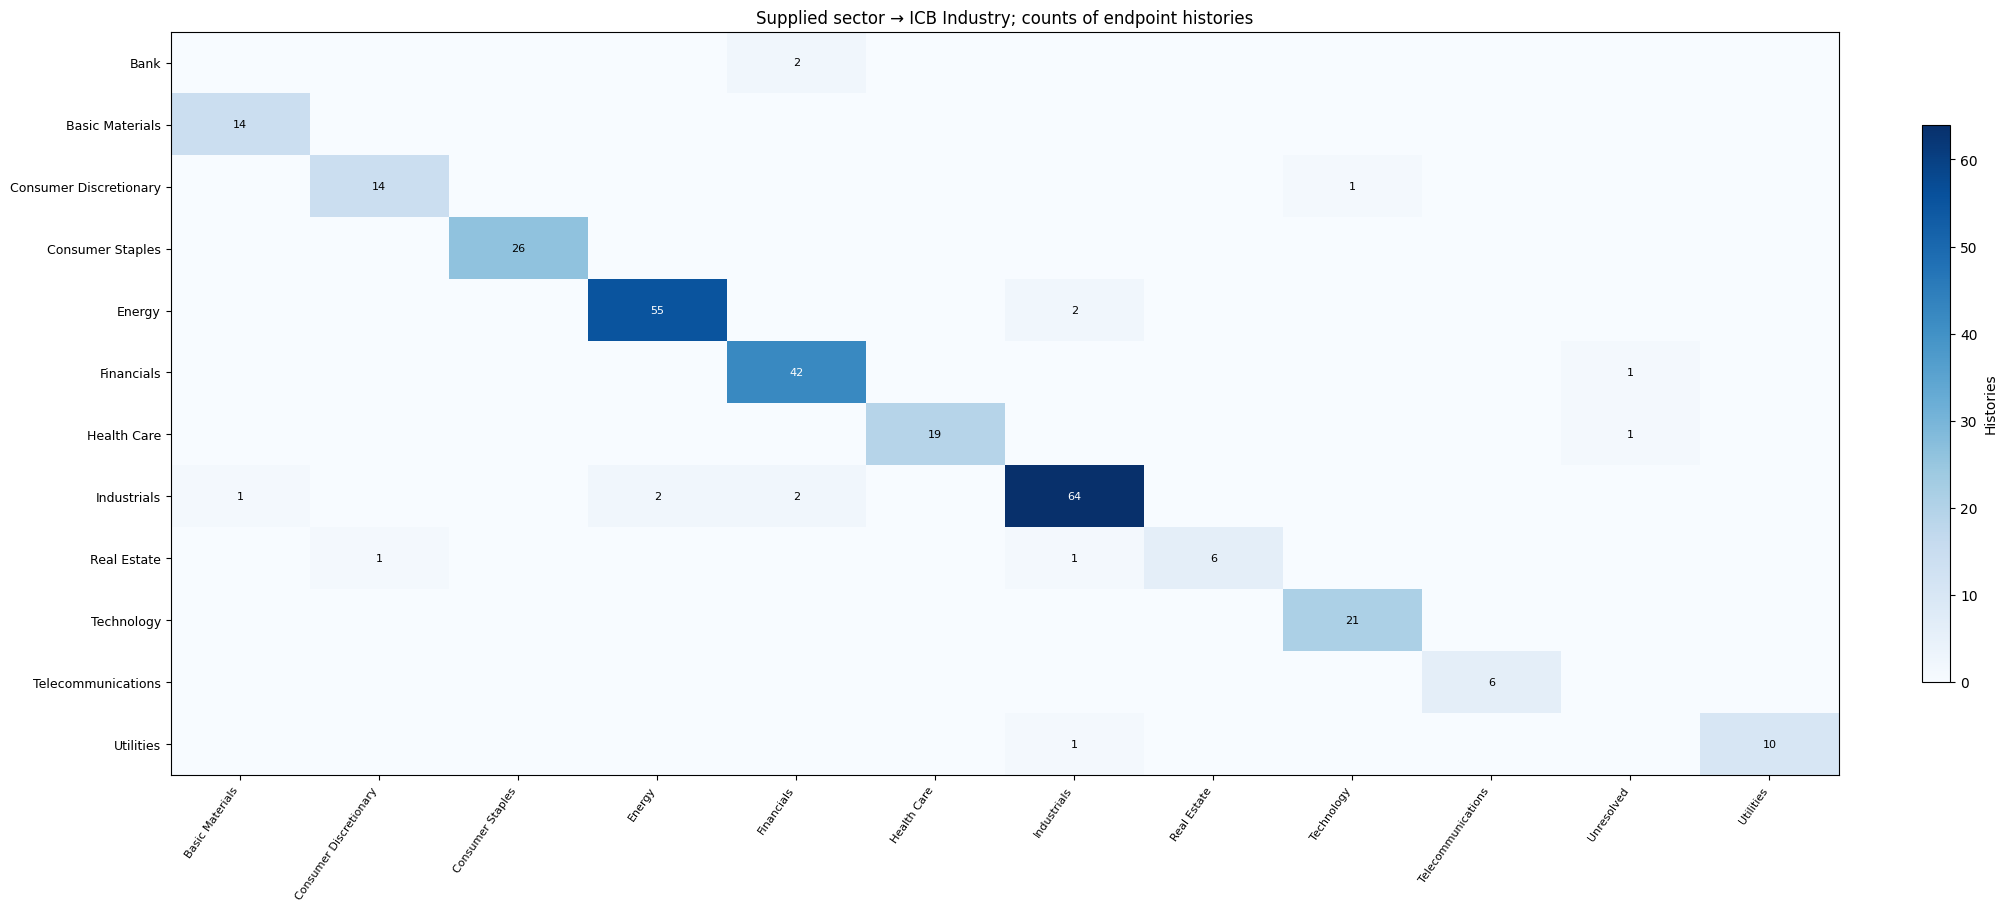

icb_sector_name,Aerospace and Defense,Alternative Energy,Automobiles and Parts,Banks,Chemicals,Construction and Materials,Consumer Services,Electricity,Electronic and Electrical Equipment,Finance and Credit Services,Food Producers,"Gas, Water and Multi-utilities",General Industrials,Health Care Providers,Household Goods and Home Construction,Industrial Engineering,Industrial Materials,Industrial Metals and Mining,Industrial Support Services,Industrial Transportation,Investment Banking and Brokerage Services,Leisure Goods,Life Insurance,Media,Medical Equipment and Services,Non-life Insurance,"Oil, Gas and Coal",Open End and Miscellaneous Investment Vehicles,"Personal Care, Drug and Grocery Stores",Pharmaceuticals and Biotechnology,Precious Metals and Mining,Real Estate Investment and Services,Retailers,Software and Computer Services,Technology Hardware and Equipment,Telecommunications Equipment,Telecommunications Service Providers,Travel and Leisure,Unresolved,Waste and Disposal Services
sector,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Bank,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Basic Materials,0,0,0,0,5,0,0,0,0,0,0,0,0,0,0,0,2,5,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0
Consumer Discretionary,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,2,0,2,0,0,0,0,0,0,0,0,4,1,0,0,0,3,0,0
Consumer Staples,0,0,0,0,0,0,0,0,0,0,25,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
Energy,1,8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,47,0,0,0,0,0,0,0,0,0,0,0,0,0
Financials,0,0,0,30,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,0,1,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,1,0
Health Care,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,14,0,0,0,0,0,0,0,0,1,0
Industrials,0,0,0,0,0,10,0,0,12,0,0,0,5,0,0,7,1,0,2,28,1,0,0,0,0,0,2,1,0,0,0,0,0,0,0,0,0,0,0,0
Real Estate,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6,0,0,0,0,0,0,0,0


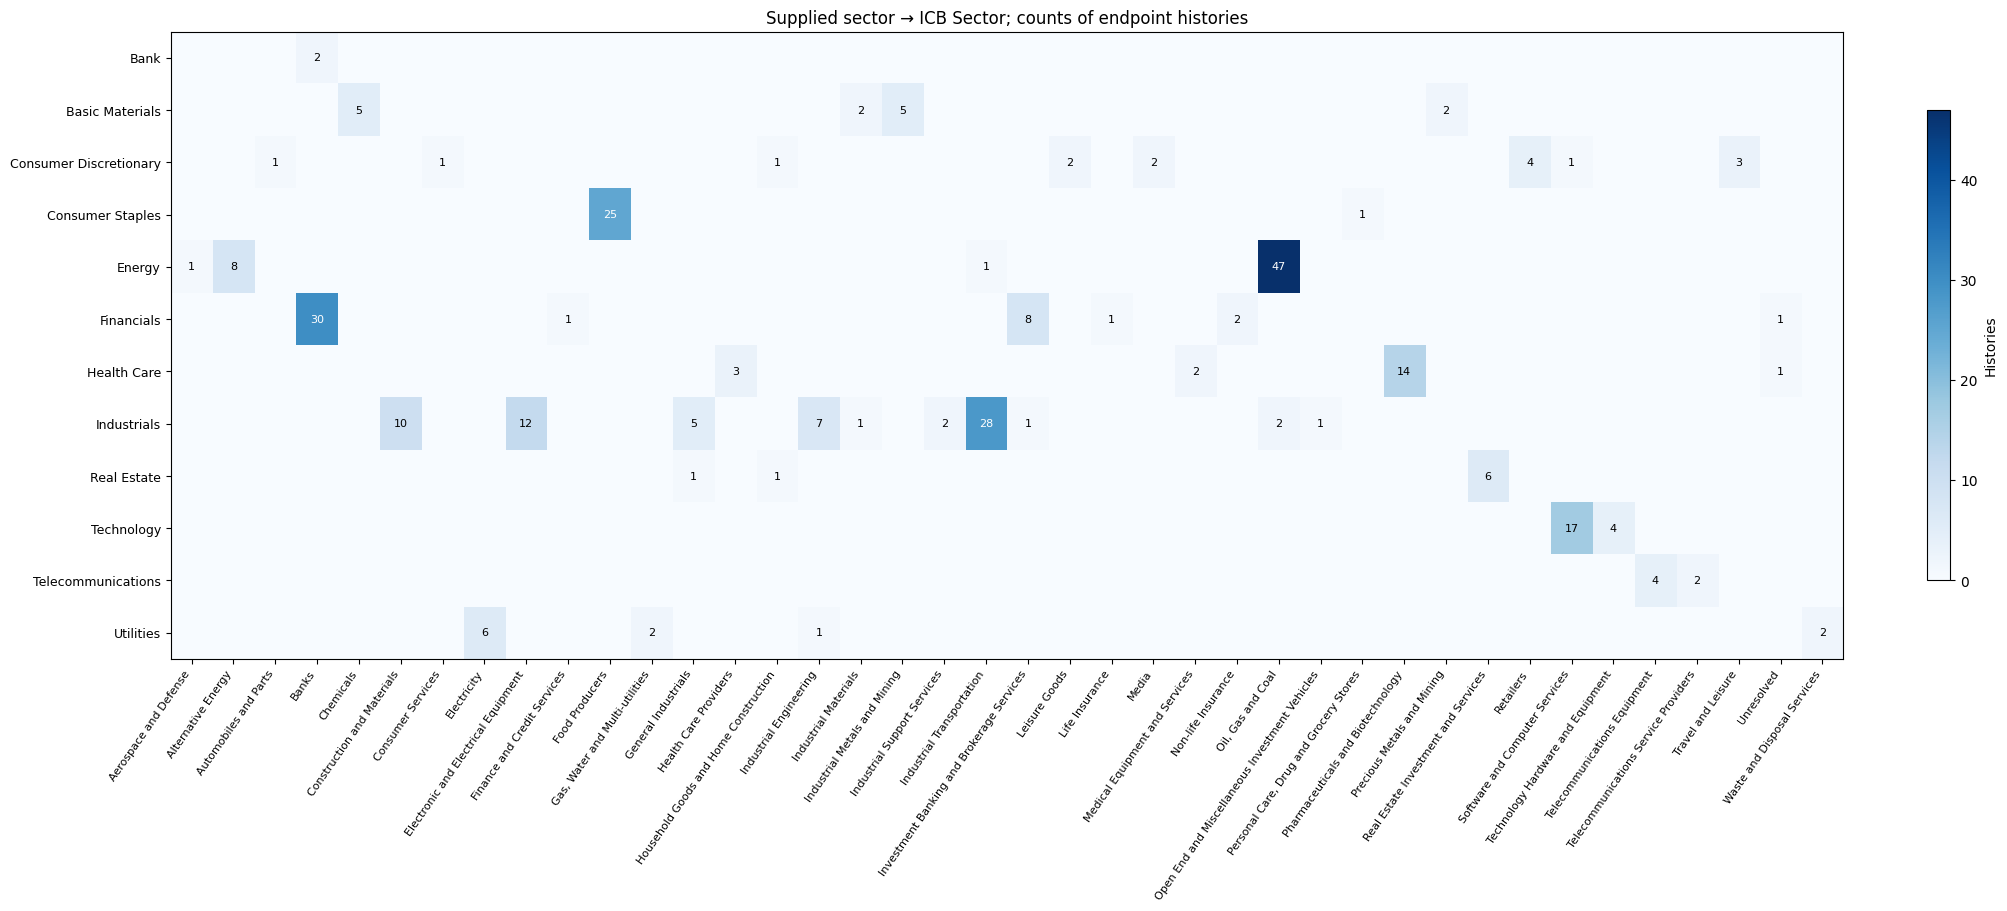

In [8]:
cross_tabs = {}
for level in ["Industry", "Sector"]:
    fig, ax = plt.subplots(figsize=(20, 9), constrained_layout=True)
    prefix = LEVELS[level][0]
    target = endpoint_mapping[f"icb_{prefix}_name"].replace("", "Unresolved")
    table = pd.crosstab(endpoint_mapping["sector"].fillna("Unknown supplied label"), target)
    cross_tabs[level] = table
    display(HTML(f"<h4>Original label → ICB {level}: all endpoint histories</h4>"))
    display(HTML('<div style="overflow:auto">' + table.to_html() + '</div>'))
    image = ax.imshow(table.to_numpy(), aspect="auto", cmap="Blues")
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=55, ha="right", fontsize=8)
    ax.set_yticks(range(len(table.index)), table.index, fontsize=9)
    for row, col in zip(*np.where(table.to_numpy() > 0)):
        value = table.iloc[row, col]
        ax.text(col, row, str(value), ha="center", va="center", fontsize=8,
                color="white" if value > table.to_numpy().max() / 2 else "black")
    ax.set_title(f"Supplied sector → ICB {level}; counts of endpoint histories")
    fig.colorbar(image, ax=ax, label="Histories", shrink=0.75)
    plt.show()

### Are finer groups large enough for dependence analysis?

For each level and sample, report group sizes, singleton groups, and the number of
unique possible within-group pairs, n(n−1)/2. These are classification-based pair
counts before checking return availability. Unresolved histories are excluded from
group/pair calculations and reported separately above. No correlations are used
to choose or adjust the classifications.
The two user-confirmed manual bank assignments are included in the group counts.

,Sample,Level,Mapped stocks,Groups,Singleton groups,Stocks in groups of >=2,Possible internal pairs,Internal share of mapped pairs
0,All endpoint histories,Industry,290,11,0,290,5921,0.141
1,All endpoint histories,Supersector,290,20,2,288,4700,0.112
2,All endpoint histories,Sector,290,39,7,283,2927,0.070
3,All endpoint histories,Subsector,290,71,28,262,1726,0.041
4,Five-year selected sample,Industry,195,11,0,195,2423,0.128
5,Five-year selected sample,Supersector,195,19,1,194,1907,0.101
6,Five-year selected sample,Sector,195,34,8,187,1294,0.068
7,Five-year selected sample,Subsector,195,62,31,164,809,0.043


Sample,Level,Code,Group,Stocks,Possible internal pairs
All endpoint histories,Sector,601010,"Oil, Gas and Coal",49,1176
All endpoint histories,Sector,301010,Banks,32,496
All endpoint histories,Sector,502060,Industrial Transportation,29,406
All endpoint histories,Sector,451020,Food Producers,25,300
All endpoint histories,Sector,101010,Software and Computer Services,18,153
All endpoint histories,Sector,201030,Pharmaceuticals and Biotechnology,14,91
All endpoint histories,Sector,502020,Electronic and Electrical Equipment,12,66
All endpoint histories,Sector,501010,Construction and Materials,10,45
All endpoint histories,Sector,302020,Investment Banking and Brokerage Services,9,36
All endpoint histories,Sector,502040,Industrial Engineering,8,28


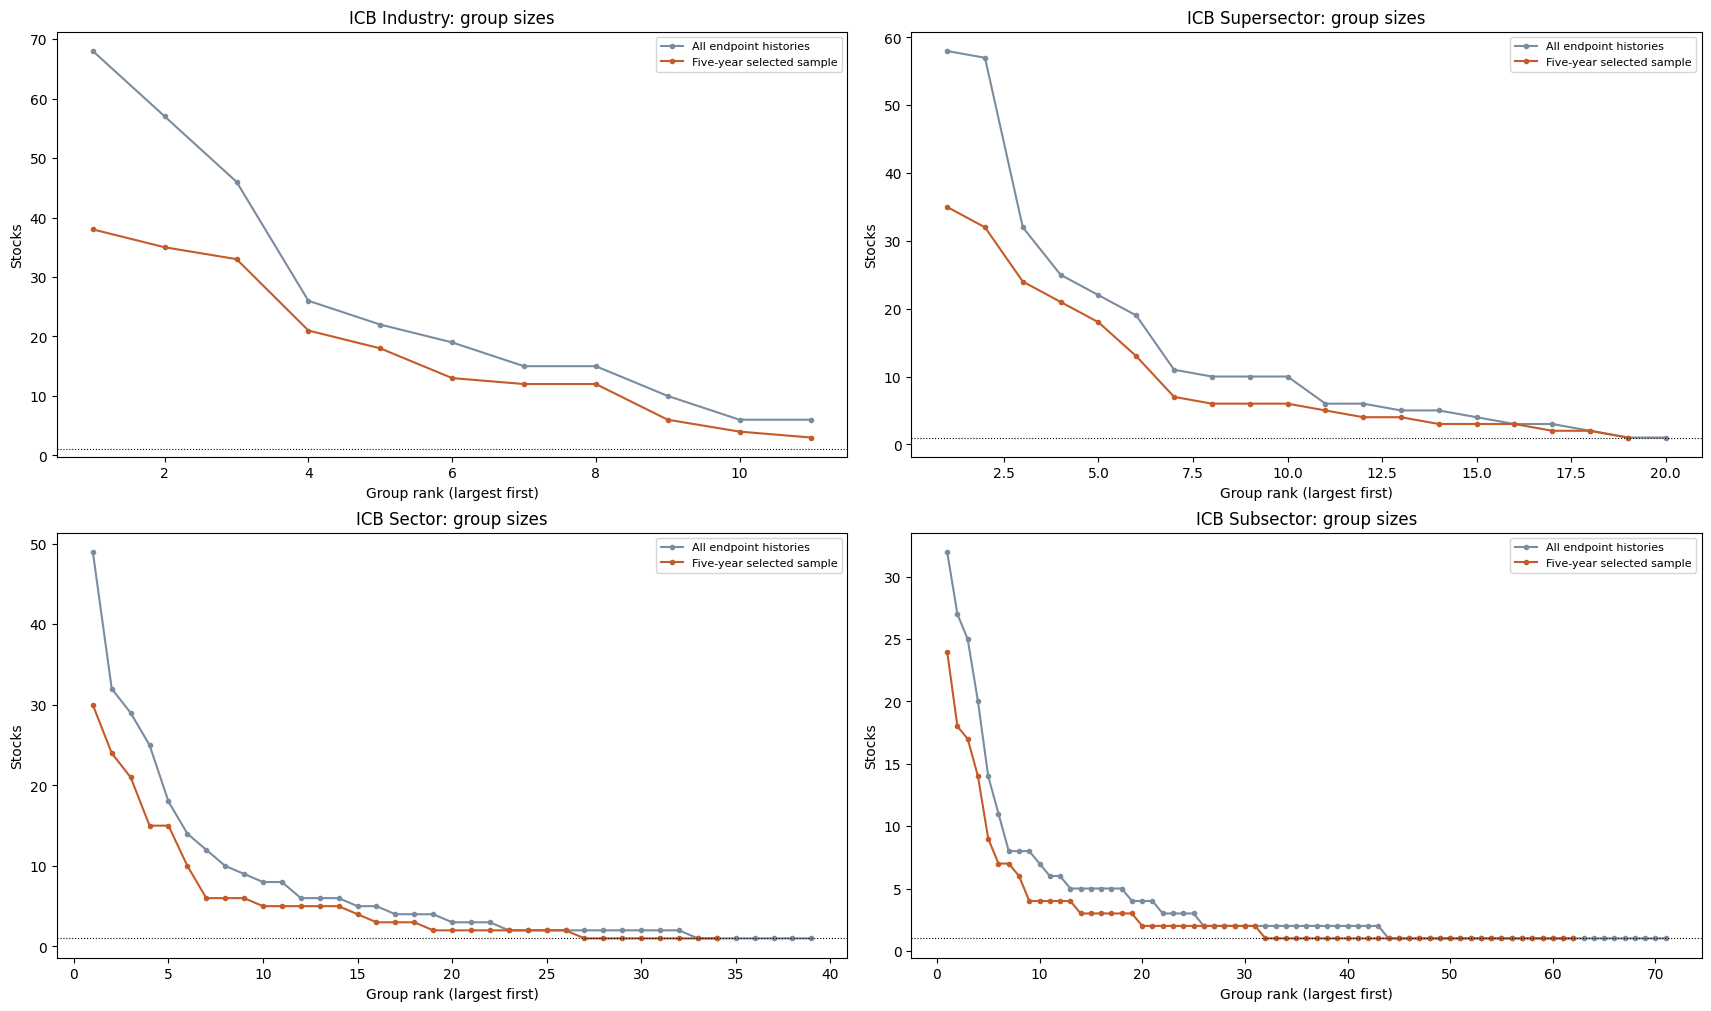

In [9]:
group_rows, group_summary_rows = [], []
for sample_name, sample in samples.items():
    mapped_sample = sample.loc[sample["classification_status"].isin(["verified", "manual"])]
    for level, (prefix, _) in LEVELS.items():
        counts = mapped_sample.groupby([f"icb_{prefix}_code", f"icb_{prefix}_name"]).size()
        for (number, name), count in counts.items():
            group_rows.append({"Sample": sample_name, "Level": level, "Code": number,
                               "Group": name, "Stocks": int(count),
                               "Possible internal pairs": int(count * (count - 1) // 2)})
        pairs = int((counts * (counts - 1) // 2).sum())
        known_n = int(counts.sum())
        group_summary_rows.append({
            "Sample": sample_name, "Level": level, "Mapped stocks": known_n,
            "Groups": len(counts), "Singleton groups": int(counts.eq(1).sum()),
            "Stocks in groups of >=2": int(counts[counts.ge(2)].sum()),
            "Possible internal pairs": pairs,
            "Internal share of mapped pairs": pairs / (known_n * (known_n - 1) / 2)
            if known_n > 1 else np.nan})
group_sizes = pd.DataFrame(group_rows)
group_summary = pd.DataFrame(group_summary_rows)
display(group_summary.round(3))
searchable_table(group_sizes.loc[group_sizes["Level"].eq(INSPECTION_LEVEL)]
                 .sort_values(["Sample", "Stocks"], ascending=[True, False]),
                 "icb-group-sizes")
fig, axes = plt.subplots(2, 2, figsize=(17, 10), constrained_layout=True)
for ax, level in zip(axes.flat, LEVELS):
    subset = group_sizes.loc[group_sizes["Level"].eq(level)]
    for sample_name, color in zip(samples, ["#7b8c9e", "#c45b28"]):
        values = subset.loc[subset["Sample"].eq(sample_name), "Stocks"].sort_values(
            ascending=False).to_numpy()
        ax.plot(np.arange(1, len(values) + 1), values, marker=".", label=sample_name, color=color)
    ax.axhline(1, color="black", linestyle=":", linewidth=0.8)
    ax.set(title=f"ICB {level}: group sizes", xlabel="Group rank (largest first)", ylabel="Stocks")
    ax.legend(fontsize=8)
plt.show()

### Inspect the companies behind the broad labels

Show banking, technology, and originally industrial companies with their published
hierarchy. Kongsberg and Frontline are highlighted explicitly. The published ICB
classification is kept even if a different thematic grouping would seem useful.
A custom defence or shipping theme would be a separate analytical decision.

In [10]:
focus_mask = (
    endpoint_mapping["sector"].fillna("").str.contains(
        "bank|financ|technolog|industrial", case=False, regex=True)
    | endpoint_mapping["icb_supersector_name"].str.contains("bank|technolog", case=False)
    | endpoint_mapping.index.isin(["NO0013536151", "CY0200352116"]))
searchable_table(inspection.loc[focus_mask.to_numpy(), inspection_columns], "icb-focus-companies")
display(endpoint_mapping.loc[["NO0013536151", "CY0200352116", "NO0010161896"],
        ["name", "sector", "icb_industry_name", "icb_sector_name",
         "icb_subsector_name", "classification_status"]])
changed_source_labels = endpoint_mapping.loc[endpoint_mapping["sector_changed"],
                                            ["name", "sector_labels", "sector"]]
print(f"Endpoint histories with changing supplied labels: {len(changed_source_labels)}")
display(changed_source_labels)

Endpoint ISIN,Company,Source company ID,Original sector,Historical source labels,Selected five-year,Industry,Supersector,Sector,Subsector,Status,classification_publisher,classification_note,Unresolved reason,Source,retrieved_at
BE0003816338,"CMB,TECH",,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:02:49.292816+00:00
BMG0670A1099,AUTOSTORE HOLDINGS,,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Engineering (502040),Machinery: Industrial (50204000),verified,Euronext Live,,,Official page,2026-11-17T14:02:53.458791+00:00
BMG4660A1036,HIMALAYA SHIPPING,,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:04:02.180737+00:00
BMG5137R1088,JINHUI SHIPP TRANS,2446.0,Industrials,"('Industrials',)",True,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:03:19.333497+00:00
BMG850801025,STOLT-NIELSEN,5097.0,Industrials,"('Industrials',)",True,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:04:06.733557+00:00
BMG9156K1018,2020 BULKERS,12720.0,Industrials,"('Industrials',)",True,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:04:10.318811+00:00
CH0496451508,SOFTWAREONE HOLD,,Technology,"('Technology',)",False,Technology (10),Technology (1010),Software and Computer Services (101010),Computer Services (10101010),verified,Euronext Live,,,Official page,2026-11-17T14:07:25.057545+00:00
CY0108052115,ADS MARITIME HOLD,,Industrials,"('Industrials',)",True,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:07:50.939028+00:00
CY0200352116,FRONTLINE,6117.0,Industrials,"('Energy', 'Industrials')",True,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:07:57.011772+00:00
CY0201332216,PELAGIC CREDIT,,Industrials,"('Industrials',)",False,Industrials (50),Industrial Goods and Services (5020),Industrial Transportation (502060),Marine Transportation (50206030),verified,Euronext Live,,,Official page,2026-11-17T14:08:03.824953+00:00


,name,sector,icb_industry_name,icb_sector_name,icb_subsector_name,classification_status
stock_id,,,,,,
NO0013536151,KONGSBERG GRUPPEN,Industrials,Industrials,General Industrials,Diversified Industrials,verified
CY0200352116,FRONTLINE,Industrials,Industrials,Industrial Transportation,Marine Transportation,verified
NO0010161896,DNB BANK,Financials,Financials,Banks,Banks,verified


Endpoint histories with changing supplied labels: 12


,name,sector_labels,sector
stock_id,,,
CY0200352116,FRONTLINE,"(Energy, Industrials)",Industrials
NL0015001BF4,REFUELS,"(Energy, Utilities)",Utilities
NO0010612450,SELVAAG BOLIG,"(Consumer Discretionary, Real Estate)",Real Estate
NO0010715394,AQUALIS,"(Energy, Industrials)",Industrials
NO0010976343,M VEST WATER,"(Industrials, Utilities)",Utilities
NO0012483207,SPAREBANKEN MØRE,"(Bank, Financials)",Financials
NO0012535832,POLIGHT,"(Information Technology, Technology)",Technology
NO0012555459,ENDÚR,"(Energy, Industrials)",Industrials
NO0012916131,TECHSTEP,"(Information Technology, Technology)",Technology


## 5. Build the reusable, ISIN-keyed export

Export one row per source ISIN belonging to the endpoint histories. A predecessor
inherits only its explicitly linked endpoint's current classification, marked
as inherited. This does not assert historical classification validity. Both source
identifiers and original sector labels are retained. Unresolved classifications
have empty ICB fields and an explicit reason.

The mapping is saved only after the validation cell passes. The source cache
and CSV live in the repository's existing ignored Data directory.

The classification_status field distinguishes verified, manual, and unresolved
rows. Manual rows carry their own publisher, basis, and classification_note; the
Euronext page and its unclassified outcome remain recorded separately.


In [11]:
source_label_history = candidate_data.groupby("ISIN")["Sector"].agg(distinct_ids)
source_export = endpoint_lineage.set_index("ISIN").rename(columns={
    "latest_name": "source_name", "latest_sector": "original_latest_sector",
    "first": "source_first_date", "last": "source_last_date",
    "company_ids": "source_company_ids", "security_ids": "source_security_ids"})
source_export["original_sector_labels"] = source_label_history
source_export = source_export[
    ["stock_id", "source_name", "source_company_ids", "source_security_ids",
     "source_first_date", "source_last_date", "original_latest_sector",
     "original_sector_labels", "selected_five_year", "link_evidence"]]
mapping = source_export.join(classifications, on="stock_id", validate="many_to_one").reset_index()
mapping["endpoint_name"] = mapping["stock_id"].map(endpoint_mapping["name"])
mapping["endpoint_original_sector"] = mapping["stock_id"].map(endpoint_mapping["sector"])
mapping["mapping_method"] = np.select(
    [mapping["classification_status"].eq("unresolved"), mapping["ISIN"].eq(mapping["stock_id"])],
    ["unresolved", "direct_endpoint"], default="inherited_current_endpoint")
mapping["classification_basis"] = "current_snapshot_not_historical"
mapping["classification_system"] = "ICB"
mapping.loc[mapping["classification_status"].eq("manual"), "classification_basis"] = (
    "user_confirmed_bank_not_official_icb")
mapping["snapshot_id"] = snapshot_id
mapping["financial_source"] = SOURCE_NAME
mapping["financial_source_sha256"] = source_hash
for column in ["source_company_ids", "source_security_ids"]:
    mapping[column] = mapping[column].map(lambda values: json.dumps([str(int(v)) for v in values]))
mapping["original_sector_labels"] = mapping["original_sector_labels"].map(
    lambda values: json.dumps(list(values), ensure_ascii=False))
for column in ["source_first_date", "source_last_date"]:
    mapping[column] = mapping[column].dt.strftime("%Y-%m-%d")
mapping = mapping.sort_values(["stock_id", "ISIN"]).reset_index(drop=True)
display(mapping.head())
print(f"Proposed export: {len(mapping)} ISIN rows for {mapping['stock_id'].nunique()} endpoint histories.")

,ISIN,stock_id,source_name,source_company_ids,source_security_ids,source_first_date,...,mapping_method,classification_basis,classification_system,snapshot_id,financial_source,financial_source_sha256
0,BE0003816338,BE0003816338,"CMB,TECH",[],[],2025-08-20,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
1,BMG0451H2087,BMG0451H2087,ARCHER,[],[],2024-05-07,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
2,BMG0670A1099,BMG0670A1099,AUTOSTORE HOLDINGS,[],[],2021-10-20,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
3,BMG0702P1086,BMG0702P1086,BW ENERGY LIMITED,"[""12748""]","[""1305295""]",2020-02-19,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
4,BMG1466R1732,BMG1466R1732,BORR DRILLING,"[""12565""]","[""1303306""]",2021-12-14,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...


Proposed export: 308 ISIN rows for 292 endpoint histories.


## 6. Validate the mapping and demonstrate a safe join

Check identity continuity, overlap prevention, export coverage, hierarchy integrity,
and source traceability. Exercise the parser with the saved official pages and
synthetic malformed/conflicting cases. Confirm that mapping the financial observations
is a many-to-one join that preserves both the row count and supplied sector labels.

In [12]:
assert mapping["ISIN"].is_unique
assert set(mapping["ISIN"]) == set(endpoint_lineage["ISIN"])
assert set(mapping["stock_id"]) == set(candidates)
assert mapping.groupby("stock_id")["selected_five_year"].nunique().eq(1).all()
assert mapping.loc[mapping["selected_five_year"], "stock_id"].nunique() == len(stock_ids)
assert mapping.loc[mapping["ISIN"].eq(mapping["stock_id"])].shape[0] == len(candidates)
for name, isins in explicit.items():
    assert len({stock_for_isin[i] for i in isins}) == 1, name
for stock_id, group in endpoint_lineage.groupby("stock_id"):
    spans = group.sort_values("first")
    assert spans["first"].iloc[1:].reset_index(drop=True).gt(
        spans["last"].iloc[:-1].reset_index(drop=True)).all()
# The joining helper must reject overlapping spans even with a proposed manual link.
overlap_pair = next((list(group.index[:2]) for _, group in stable.groupby("company_ids")
                     if len(group) > 1 and any(
                         profiles.loc[a, "first"] <= profiles.loc[b, "last"] and
                         profiles.loc[b, "first"] <= profiles.loc[a, "last"]
                         for a, b in [tuple(group.index[:2])])), None)
assert overlap_pair is not None
before_identity = {key: set(value) for key, value in history.items()}
assert not join_isins(overlap_pair, "validation: unsupported overlapping classes")
assert history == before_identity
assert selected["issuer_key"].is_unique
assert audit["coverage_eligible"].equals(audit["boundary_ok"] & audit["coverage_ok"])
reference_path = root / "sandbox" / "EDA" / "interpolation_comparison" / "observed.json.gz"
if reference_path.exists():
    with gzip.open(reference_path, "rt") as handle:
        reference = json.load(handle)
    if reference["provenance"]["source_sha256"] == source_hash:
        assert set(stock_ids) == set(reference["provenance"]["stocks"])
        print("Five-year stock identities match the saved dependence analysis.")

verified = mapping["classification_status"].eq("verified")
manual = mapping["classification_status"].eq("manual")
mapped = verified | manual
assert mapping["classification_status"].isin(["verified", "manual", "unresolved"]).all()
assert set(mapping.loc[manual, "stock_id"]) == set(manual_bank_isins)
assert mapping.loc[manual, "classification_publisher"].eq("Manual (user-confirmed)").all()
assert mapping.loc[manual, "classification_note"].str.contains("User confirmed").all()
for isin in manual_bank_isins:
    assert all(classifications.loc[isin, column] == value
               for column, value in bank_hierarchy.items())
    assert official_classifications.loc[isin, "unresolved_reason"] == "no_published_icb_table"
# The manually assigned codes must match the bank hierarchy already published for DNB.
assert all(classifications.loc["NO0010161896", column] == value
           for column, value in bank_hierarchy.items())
icb_columns = [f"icb_{prefix}_{suffix}" for prefix, _ in LEVELS.values() for suffix in ("code", "name")]
assert mapping.loc[~mapped, icb_columns].eq("").all().all()
assert mapping.loc[~mapped, "unresolved_reason"].ne("").all()
assert mapping.loc[mapped, "unresolved_reason"].eq("").all()
assert mapping.loc[mapped, "classification_isin"].equals(mapping.loc[mapped, "stock_id"])
for level, (prefix, width) in LEVELS.items():
    codes = mapping.loc[mapped, f"icb_{prefix}_code"]
    assert codes.str.fullmatch(rf"\d{{{width}}}").all()
    assert mapping.loc[mapped].groupby(f"icb_{prefix}_code")[f"icb_{prefix}_name"].nunique().eq(1).all()
for parent, child in zip(list(LEVELS.values())[:-1], list(LEVELS.values())[1:]):
    assert all(c.startswith(p) for p, c in zip(
        mapping.loc[mapped, f"icb_{parent[0]}_code"], mapping.loc[mapped, f"icb_{child[0]}_code"]))
for path in mapping.loc[verified, "evidence_cache"].unique():
    assert (root / path).is_file()
for _, row in mapping.loc[verified].drop_duplicates("stock_id").iterrows():
    payload = json.loads(gzip.decompress((root / row["evidence_cache"]).read_bytes()))
    parsed = parse_icb(payload, row["classification_isin"])
    assert parsed["classification_status"] == "verified"
    assert all(parsed[column] == row[column] for column in icb_columns)
    assert row["source_url"] in json.loads(row["candidate_source_urls"])
    assert row["retrieved_at"]
for entry in manifest["requests"].values():
    raw_bytes = gzip.decompress((root / entry["cache_path"]).read_bytes())
    assert hashlib.sha256(raw_bytes).hexdigest() == entry["content_sha256"]

# Actual saved official pages are fixtures; compare with cached content, not assumed future classifications.
fixture_isins = ["NO0013536151", "CY0200352116", "NO0010161896"]
for isin in fixture_isins:
    row = classifications.loc[isin]
    assert row["classification_status"] == "verified", f"Inspect example coverage: {isin}"
fixture = json.loads(gzip.decompress((root / classifications.loc[
    fixture_isins[0], "evidence_cache"]).read_bytes()))
fixture_text = fixture["markdown"]
expected_subsector = classifications.loc[fixture_isins[0], "icb_subsector_code"]
assert parse_icb(fixture, fixture_isins[0])["icb_subsector_code"] == expected_subsector
assert parse_icb(fixture, "NO0000000000")["unresolved_reason"] == "security_identity_not_verified"
missing_fixture = {**fixture, "markdown": re.split(
    r"ICB\s+SECTORIAL\s+CLASSIFICATION", fixture_text, flags=re.I)[0]}
assert parse_icb(missing_fixture, fixture_isins[0])["unresolved_reason"] == "no_published_icb_table"
malformed = {**fixture, "markdown": re.sub(
    r'\|\s*Subsector\s*\|[^\n]*', "", fixture_text, flags=re.I)}
assert parse_icb(malformed, fixture_isins[0])["unresolved_reason"] == "incomplete_or_malformed_icb_table"
conflicting = {**fixture, "markdown": fixture_text + "\n| Industry | **99, Conflicting industry** |"}
assert parse_icb(conflicting, fixture_isins[0])["unresolved_reason"] == "conflicting_icb_table"
inconsistent = {**fixture, "markdown": fixture_text.replace(expected_subsector, "99000000")}
assert parse_icb(inconsistent, fixture_isins[0])["unresolved_reason"] == "inconsistent_icb_hierarchy"
assert parse_icb({"metadata": {"statusCode": 404}}, fixture_isins[0])["unresolved_reason"] == "page_not_found"
no_table_rows = official_classifications.loc[
    official_classifications["unresolved_reason"].eq("no_published_icb_table")]
if len(no_table_rows):
    isin = no_table_rows.index[0]
    payload = json.loads(gzip.decompress((root / no_table_rows.iloc[0]["evidence_cache"]).read_bytes()))
    assert parse_icb(payload, isin)["unresolved_reason"] == "no_published_icb_table"
assert group_summary["Mapped stocks"].le(group_summary["Sample"].map(
    coverage_summary["Histories"])).all()
for _, row in group_summary.iterrows():
    group = group_sizes.loc[group_sizes["Sample"].eq(row["Sample"])
                            & group_sizes["Level"].eq(row["Level"])]
    assert group["Stocks"].sum() == row["Mapped stocks"]
    assert group["Possible internal pairs"].sum() == row["Possible internal pairs"]
    assert (group["Stocks"] * (group["Stocks"] - 1) // 2).equals(group["Possible internal pairs"])
for level, table in cross_tabs.items():
    assert table.to_numpy().sum() == len(candidates)

# Demonstrate application without overwriting the original financial sector.
join_columns = ["ISIN", "stock_id", "mapping_method", "classification_status", *icb_columns]
joined_example = candidate_data[["Date", "ISIN", "Name", "Sector"]].merge(
    mapping[join_columns], on="ISIN", how="left", validate="many_to_one", sort=False)
assert len(joined_example) == len(candidate_data)
assert joined_example["Sector"].reset_index(drop=True).equals(
    candidate_data["Sector"].reset_index(drop=True))
assert joined_example["stock_id"].notna().all()
display(joined_example.head())
endpoint_lookup = mapping.loc[mapping["ISIN"].eq(mapping["stock_id"])].set_index("stock_id")
selected_with_icb = selected.join(endpoint_lookup[icb_columns], validate="one_to_one")
assert len(selected_with_icb) == len(selected)
assert selected_with_icb.index.equals(selected.index)
display(selected_with_icb[["name", "sector", "icb_sector_name", "icb_subsector_name"]].head())
print("Identity, selection, parser, hierarchy, evidence, pair counts, and safe-join checks passed.")

Five-year stock identities match the saved dependence analysis.


,Date,ISIN,Name,Sector,stock_id,mapping_method,...,icb_supersector_code,icb_supersector_name,icb_sector_code,icb_sector_name,icb_subsector_code,icb_subsector_name
0,1980-01-02,NO0003733800,Orkla,Consumer Staples,NO0003733800,direct_endpoint,...,4510,"Food, Beverage and Tobacco",451020,Food Producers,45102020,Food Products
1,1980-01-02,NO0005052605,Norsk Hydro,Basic Materials,NO0005052605,direct_endpoint,...,5510,Basic Resources,551020,Industrial Metals and Mining,55102035,Aluminum
2,1980-01-03,NO0003733800,Orkla,Consumer Staples,NO0003733800,direct_endpoint,...,4510,"Food, Beverage and Tobacco",451020,Food Producers,45102020,Food Products
3,1980-01-03,NO0005052605,Norsk Hydro,Basic Materials,NO0005052605,direct_endpoint,...,5510,Basic Resources,551020,Industrial Metals and Mining,55102035,Aluminum
4,1980-01-04,NO0003053605,Storebrand,Financials,NO0003053605,direct_endpoint,...,3030,Insurance,303010,Life Insurance,30301010,Life Insurance


,name,sector,icb_sector_name,icb_subsector_name
stock_id,,,,
NO0010636491,GRONG SPAREBANK,Bank,Banks,Banks
NO0010808405,ROMERIKE SPAREBK,Bank,Banks,Banks
SE0015193412,AKOBO MINERALS,Basic Materials,Precious Metals and Mining,Gold Mining
NO0010950249,BERGEN CARBON SOL,Basic Materials,Chemicals,Chemicals and Synthetic Fibers
NO0010657505,BORREGAARD,Basic Materials,Chemicals,Specialty Chemicals


Identity, selection, parser, hierarchy, evidence, pair counts, and safe-join checks passed.


## 7. Save, reload, and summarize

The UTF-8 CSV is keyed by source ISIN and includes unresolved rows. Read identifier
and classification-code columns as strings. Empty ICB fields mean unavailable;
use the status/reason columns rather than silently replacing them with original labels.

Join raw observations on ISIN with a many-to-one check. For a reconstructed
stock panel, first restrict to rows where ISIN equals stock_id, then join on
stock_id. Joining the entire alias table on stock_id would duplicate histories.

In [13]:
# Persist a stable string representation, then require an exact CSV round trip.
export = mapping.fillna("").astype(str)
export.to_csv(output_path, index=False, encoding="utf-8", lineterminator="\n")
reloaded = pd.read_csv(output_path, dtype=str, keep_default_na=False)
pd.testing.assert_frame_equal(reloaded, export)
manifest["mapping_file"] = output_path.relative_to(root).as_posix()
manifest["mapping_sha256"] = hashlib.sha256(output_path.read_bytes()).hexdigest()
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print(f"Saved {len(export)} rows to {output_path.relative_to(root)}")
print(f"Source snapshot: {snapshot_id}; requests made during this run: {network_requests}")
if offline:
    assert network_requests == 0
    print("Offline verification passed: no collection requests were made.")

selected_groups = group_summary.loc[
    group_summary["Sample"].eq("Five-year selected sample")
    & group_summary["Level"].eq(INSPECTION_LEVEL)].iloc[0]
industry_fragments = (cross_tabs["Industry"].drop(columns="Unresolved", errors="ignore") > 0).sum(axis=1)
industrial_detail = endpoint_mapping.loc[
    endpoint_mapping["sector"].eq("Industrials")
    & endpoint_mapping["classification_status"].eq("verified")]
findings = pd.DataFrame([
    {"Finding": "Manual bank assignments",
     "Observed result": f"{int(endpoint_mapping['classification_status'].eq('manual').sum())} user-confirmed banks",
     "Interpretation or limitation": "Grong and Romerike use the ICB Banks hierarchy by explicit user instruction, without claiming an official Euronext assignment."},
    {"Finding": "Endpoint coverage",
     "Observed result": f"{int(coverage_summary.iloc[0]['Mapped'])}/{len(endpoint_mapping)} mapped "
                        f"({int(coverage_summary.iloc[0]['Verified'])} verified, "
                        f"{int(coverage_summary.iloc[0]['Manual'])} manual)",
     "Interpretation or limitation": "Coverage is measured, not assumed to be complete."},
    {"Finding": "Five-year sample coverage",
     "Observed result": f"{int(coverage_summary.iloc[1]['Mapped'])}/{len(stock_ids)} mapped "
                        f"({int(coverage_summary.iloc[1]['Verified'])} verified, "
                        f"{int(coverage_summary.iloc[1]['Manual'])} manual)",
     "Interpretation or limitation": "Unresolved stocks stay in the export; exclude them explicitly in group comparisons."},
    {"Finding": "Missing classifications",
     "Observed result": f"{len(unresolved)} unresolved endpoint histories",
     "Interpretation or limitation": "Two explicitly user-confirmed bank assignments are marked manual; other unsupported cases remain unresolved."},
    {"Finding": "Original-label fragmentation",
     "Observed result": f"{int(industry_fragments.gt(1).sum())} supplied labels span multiple ICB Industries",
     "Interpretation or limitation": "Different classification schemes can legitimately disagree; inspect the cross-tabs."},
    {"Finding": "Detail within supplied Industrials",
     "Observed result": f"{len(industrial_detail)} classified histories span "
                        f"{industrial_detail['icb_sector_code'].nunique()} ICB Sectors and "
                        f"{industrial_detail['icb_subsector_code'].nunique()} Subsectors",
     "Interpretation or limitation": "Finer ICB levels distinguish activities hidden by the broad industry label."},
    {"Finding": f"Selected-sample ICB {INSPECTION_LEVEL} groups",
     "Observed result": f"{int(selected_groups['Groups'])} groups; {int(selected_groups['Singleton groups'])} singletons; "
                        f"{int(selected_groups['Possible internal pairs'])} possible internal pairs",
     "Interpretation or limitation": "Singletons have no within-group pair estimate; return support is checked later."},
    {"Finding": "Supported predecessor ISINs",
     "Observed result": f"{int(mapping['mapping_method'].eq('inherited_current_endpoint').sum())} inherited verified rows",
     "Interpretation or limitation": "Inheritance applies the current endpoint snapshot; it does not establish historical membership."},
    {"Finding": "Temporal scope",
     "Observed result": f"Classification snapshot {snapshot_id}; financial endpoint {END.date()}",
     "Interpretation or limitation": "Current classifications are retrospective when applied to 2021–2026; not suitable as historical facts without dated evidence."},
    {"Finding": "Identity and sampling limits",
     "Observed result": f"{int(endpoint_mapping['company_id'].isna().sum())} endpoint histories lack a source company ID",
     "Interpretation or limitation": "Endpoint universe has survivorship limits. Exact-ISIN evidence can classify a stock without resolving issuer continuity."},
])
display(findings)
display(reloaded.head())

Saved 308 rows to Data/stock_sector_mapping.csv
Source snapshot: 20261117T140247570260Z; requests made during this run: 0
Offline verification passed: no collection requests were made.


,Finding,Observed result,Interpretation or limitation
0,Manual bank assignments,2 user-confirmed banks,Grong and Romerike use the ICB Banks hierarchy...
1,Endpoint coverage,"290/292 mapped (288 verified, 2 manual)","Coverage is measured, not assumed to be complete."
2,Five-year sample coverage,"195/195 mapped (193 verified, 2 manual)",Unresolved stocks stay in the export; exclude ...
3,Missing classifications,2 unresolved endpoint histories,Two explicitly user-confirmed bank assignments...
4,Original-label fragmentation,5 supplied labels span multiple ICB Industries,Different classification schemes can legitimat...
5,Detail within supplied Industrials,69 classified histories span 10 ICB Sectors an...,Finer ICB levels distinguish activities hidden...
6,Selected-sample ICB Sector groups,34 groups; 8 singletons; 1294 possible interna...,Singletons have no within-group pair estimate;...
7,Supported predecessor ISINs,16 inherited verified rows,Inheritance applies the current endpoint snaps...
8,Temporal scope,Classification snapshot 20261117T140247570260Z...,Current classifications are retrospective when...
9,Identity and sampling limits,148 endpoint histories lack a source company ID,Endpoint universe has survivorship limits. Exa...


,ISIN,stock_id,source_name,source_company_ids,source_security_ids,source_first_date,...,mapping_method,classification_basis,classification_system,snapshot_id,financial_source,financial_source_sha256
0,BE0003816338,BE0003816338,"CMB,TECH",[],[],2025-08-20,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
1,BMG0451H2087,BMG0451H2087,ARCHER,[],[],2024-05-07,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
2,BMG0670A1099,BMG0670A1099,AUTOSTORE HOLDINGS,[],[],2021-10-20,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
3,BMG0702P1086,BMG0702P1086,BW ENERGY LIMITED,"[""12748""]","[""1305295""]",2020-02-19,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
4,BMG1466R1732,BMG1466R1732,BORR DRILLING,"[""12565""]","[""1303306""]",2021-12-14,...,direct_endpoint,current_snapshot_not_historical,ICB,20261117T140247570260Z,BMG9156K1018_10.09.2026_14.59.34.csv,e7b31e7bd670a23c6e10c6a52c707e33d4fc56c82b46bc...
